In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("smartcart_customers.csv")

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [4]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

Data Preprocessing

Handle Missing Values

In [5]:
df["Income"] = df["Income"].fillna(df["Income"].median())

In [6]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


Feature Engineering

In [7]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response'],
      dtype='object')

In [8]:
#Age
df["Age"] = 2026-df["Year_Birth"]

In [9]:
#Date
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst=True)

reference_date = df["Dt_Customer"].max()

df["Customer_Tenure_Days"] = (reference_date-df["Dt_Customer"]).dt.days

In [10]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,88,3,8,10,4,7,0,1,69,663
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,6,2,1,1,2,5,0,0,72,113
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,42,1,8,2,10,4,0,0,61,312
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,5,2,2,0,4,6,0,0,42,139
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,15,5,5,3,6,5,0,0,45,161


In [11]:
#Total  Spending
df["Total_Spending"] = df["MntWines"] + df["MntFruits"] + df["MntMeatProducts"] + df["MntFishProducts"] + df["MntSweetProducts"] + df["MntGoldProds"]

In [12]:
#Total Children
df["Total_Children"] = df["Kidhome"] + df["Teenhome"]

In [13]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,8,10,4,7,0,1,69,663,1617,0
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,1,1,2,5,0,0,72,113,27,2
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,8,2,10,4,0,0,61,312,776,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,2,0,4,6,0,0,42,139,53,1
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,3,6,5,0,0,45,161,422,1


In [14]:
#Education

df["Education"] = df["Education"].replace({
    "Basic" : "Undergraduates" , "2n Cycle" : "Undergraduates",
    "Graduation" : "Graduates",
    "Master" : "PostGraduates" , "PhD" : "PostGraduates"
})


In [15]:
df["Education"].value_counts()


Education
Graduates         1127
PostGraduates      856
Undergraduates     257
Name: count, dtype: int64

In [16]:
#Marital Status

df["Living_with"] = df["Marital_Status"].replace({
    "Married" : "Partner" , "Together" : "Partner",
    "Single" : "Alone", "Divorced" : "Alone",
    "Widow" : "Alone" , "Absurd" : "Alone" , "YOLO" : "Alone"
})


In [17]:
df["Living_with"].value_counts()

Living_with
Partner    1444
Alone       796
Name: count, dtype: int64

Drop Columns

In [18]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Living_with
0,5524,1957,Graduates,Single,58138.0,0,0,2012-09-04,58,635,...,10,4,7,0,1,69,663,1617,0,Alone
1,2174,1954,Graduates,Single,46344.0,1,1,2014-03-08,38,11,...,1,2,5,0,0,72,113,27,2,Alone
2,4141,1965,Graduates,Together,71613.0,0,0,2013-08-21,26,426,...,2,10,4,0,0,61,312,776,0,Partner
3,6182,1984,Graduates,Together,26646.0,1,0,2014-02-10,26,11,...,0,4,6,0,0,42,139,53,1,Partner
4,5324,1981,PostGraduates,Married,58293.0,1,0,2014-01-19,94,173,...,3,6,5,0,0,45,161,422,1,Partner


In [19]:
cols = ["ID" , "Year_Birth" , "Marital_Status" , "Kidhome" , "Teenhome" , "Dt_Customer" ]
spending_Col = ["MntWines" , "MntFruits" , "MntMeatProducts" , "MntFishProducts" , "MntSweetProducts" , "MntGoldProds"]

cols_to_drop = cols + spending_Col

df_cleaned = df.drop(columns=cols_to_drop)

In [20]:
df_cleaned.shape

(2240, 15)

In [21]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Living_with
0,Graduates,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,Graduates,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone
2,Graduates,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner
3,Graduates,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner
4,PostGraduates,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner


Outliers

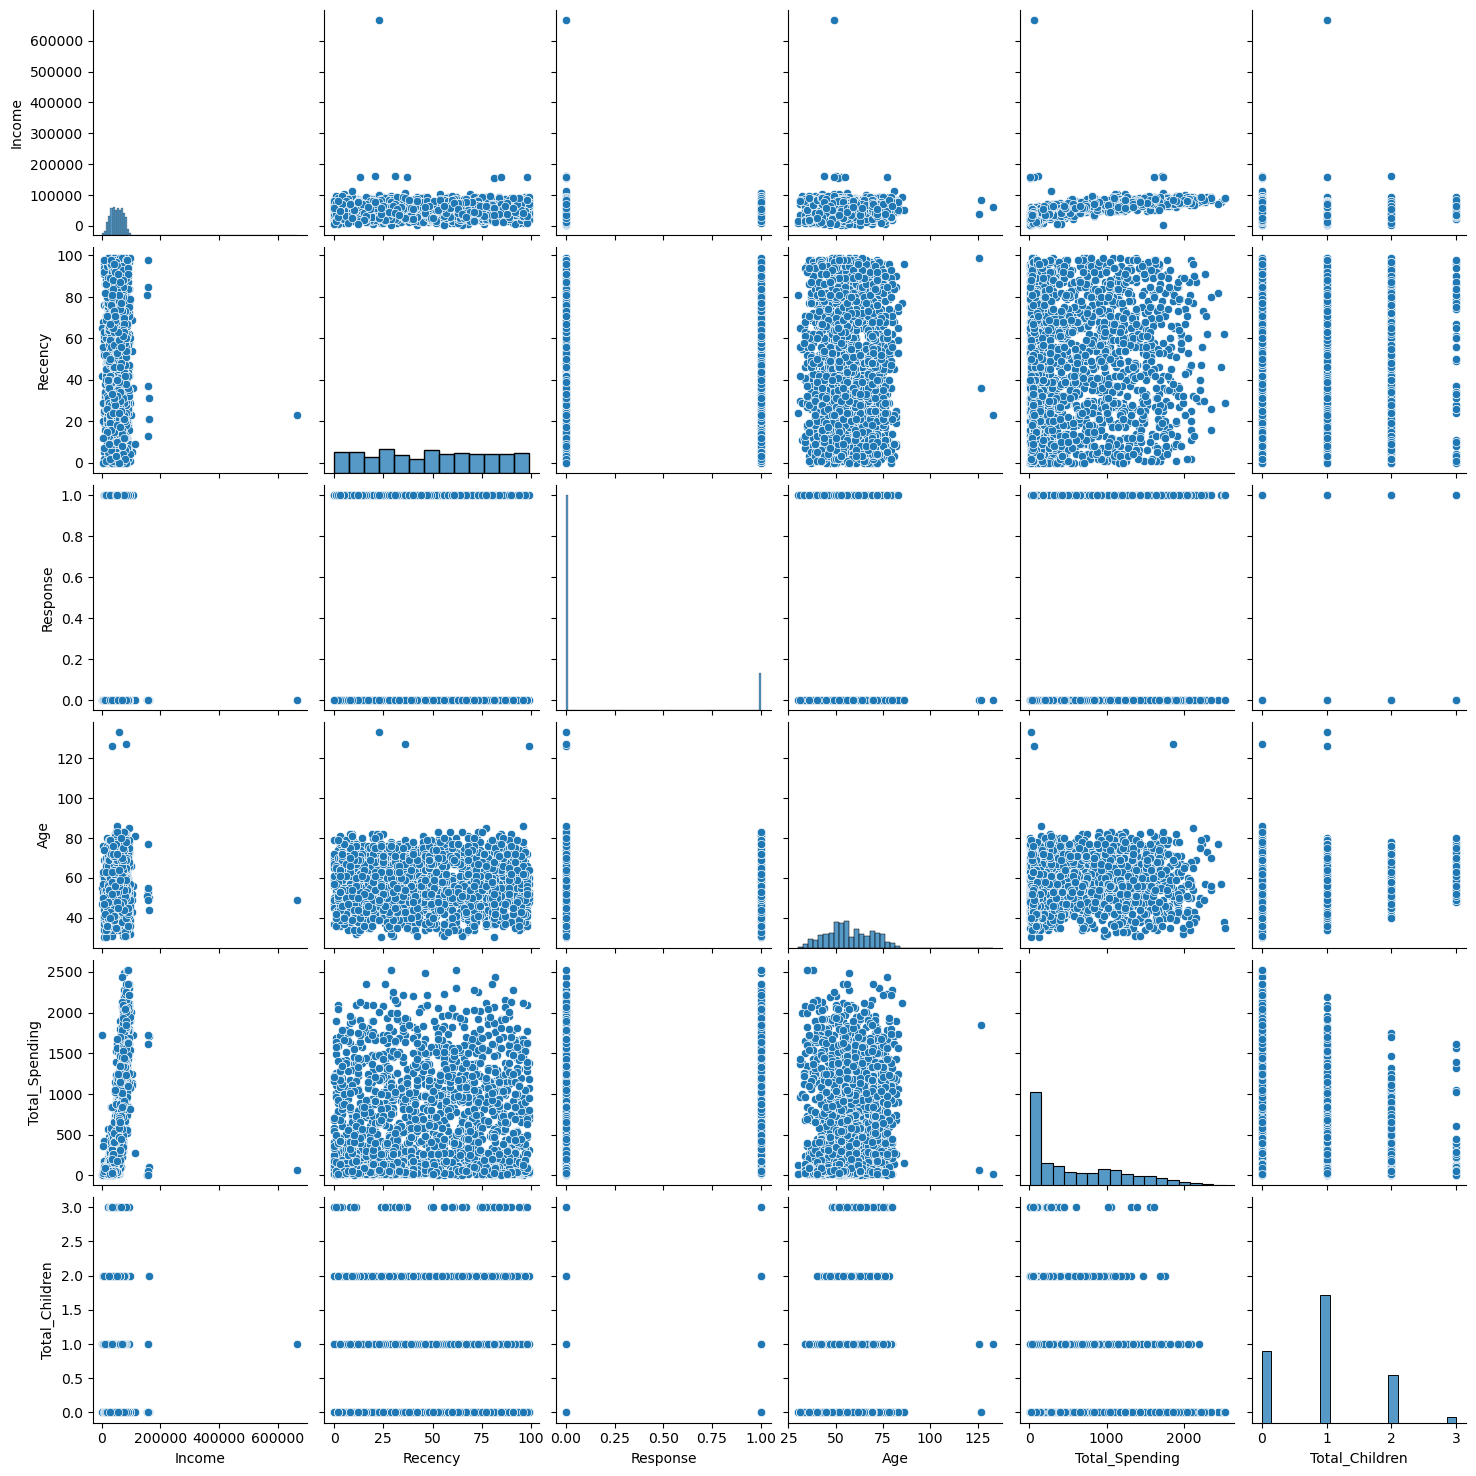

In [22]:
cols = ["Income" , "Recency" ,"Response" , "Age", "Total_Spending" , "Total_Children"]

#Relative plots of some feature pair plots
sns.pairplot(df_cleaned[cols])

In [23]:
#Remove Outlier

print("Data size with outlier" , len(df_cleaned))

df_cleaned = df_cleaned[(df_cleaned["Age"] < 90)]
df_cleaned = df_cleaned[(df_cleaned["Income"] < 600_000)]

print("Data size with outlier" , len(df_cleaned))


Data size with outlier 2240
Data size with outlier 2236


Heatmap

In [24]:
corr = df_cleaned.corr(numeric_only=True)

<Axes: >

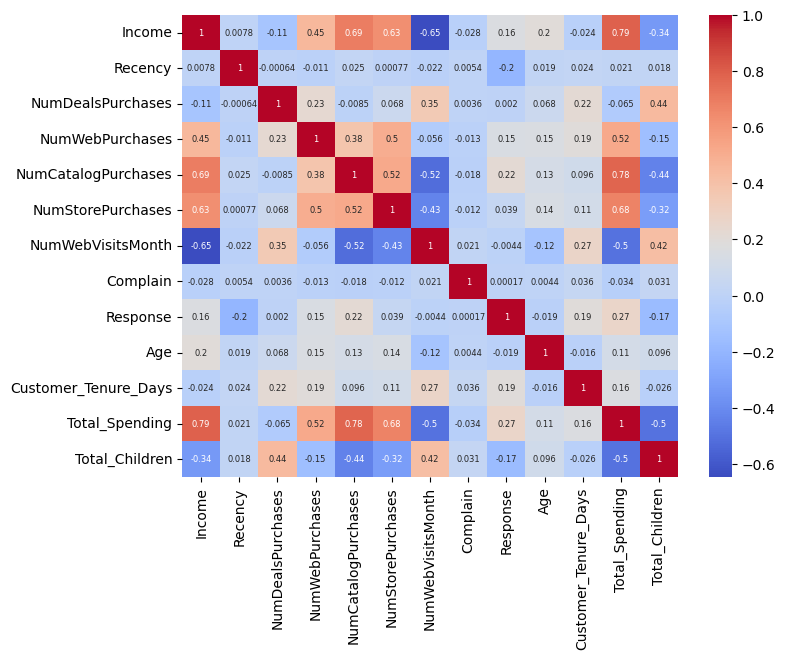

In [25]:
plt.figure(figsize=(8,6))
sns.heatmap(
    corr,
    annot=True,
    annot_kws={"size": 6},
    cmap="coolwarm"
)

Encoding

In [26]:
from sklearn.preprocessing import OneHotEncoder

In [27]:
ohe = OneHotEncoder()

cat_cols = ["Education" , "Living_with"]

enc_cols = ohe.fit_transform(df_cleaned[cat_cols])


In [28]:
enc_df = pd.DataFrame(enc_cols.toarray(), columns=ohe.get_feature_names_out(cat_cols),index=df_cleaned.index)

In [29]:
df_encoded = pd.concat([df_cleaned.drop(columns=cat_cols),enc_df] , axis=1)

In [30]:
df_encoded.shape

(2236, 18)

Scaling

In [31]:
from sklearn.preprocessing import StandardScaler

In [32]:
X= df_encoded

In [33]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [34]:
X_scaled

array([[ 0.28894655,  0.30685572,  0.34873831, ..., -0.35877969,
         1.3476353 , -1.3476353 ],
       [-0.262003  , -0.38397129, -0.16869955, ..., -0.35877969,
         1.3476353 , -1.3476353 ],
       [ 0.91842301, -0.7984675 , -0.68613742, ..., -0.35877969,
        -0.74204052,  0.74204052],
       ...,
       [ 0.234898  ,  1.44672029, -0.68613742, ..., -0.35877969,
         1.3476353 , -1.3476353 ],
       [ 0.80780332, -1.42021181, -0.16869955, ..., -0.35877969,
        -0.74204052,  0.74204052],
       [ 0.04280841, -0.31488859,  0.34873831, ..., -0.35877969,
        -0.74204052,  0.74204052]], shape=(2236, 18))

Visualize

In [35]:
X_scaled.shape

(2236, 18)

In [36]:
#2D
from sklearn.decomposition import PCA

In [37]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

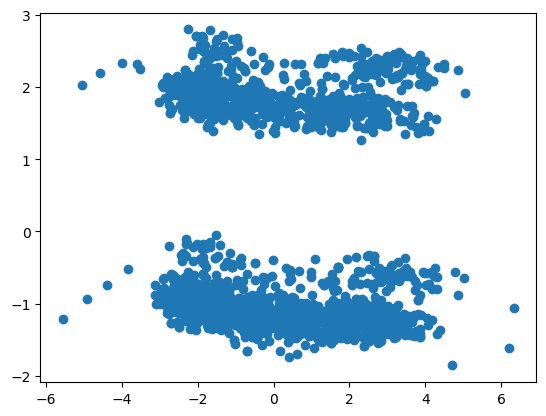

In [38]:
plt.scatter(X_pca[:,0] , X_pca[:,1])

In [39]:
pca.explained_variance_ratio_

array([0.23163158, 0.11385454])

In [40]:
#3D
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

In [41]:
pca.explained_variance_ratio_

array([0.23163158, 0.11385454, 0.10405815])

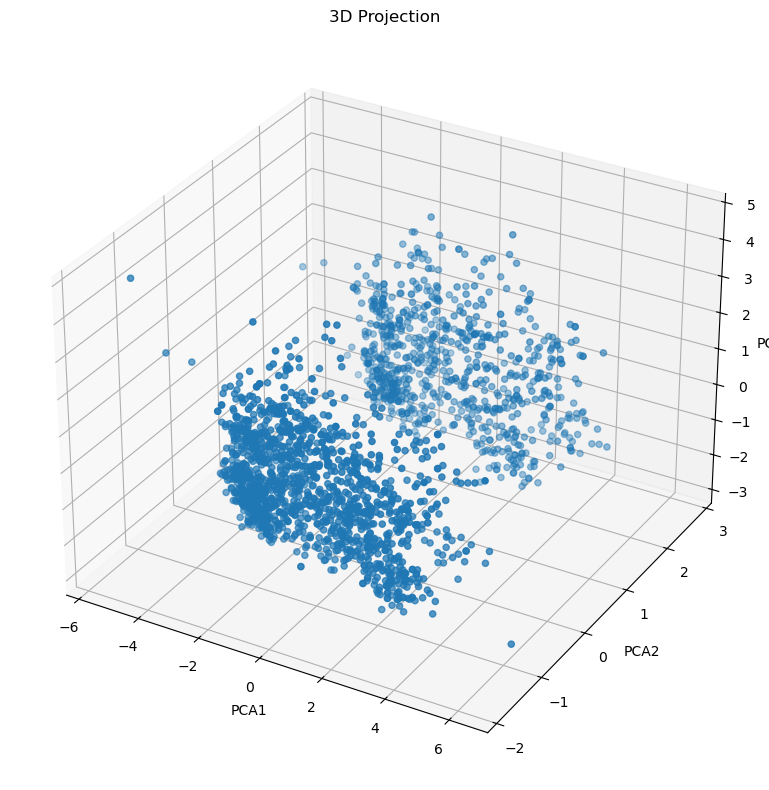

In [42]:
fig = plt.figure(figsize=(8,8))

ax = fig.add_subplot(111,projection="3d")

ax.scatter(X_pca[:,0] , X_pca[:,1] , X_pca[:,2])

ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("3D Projection")

plt.tight_layout()

Analyze K Value

1.Elbow Method

In [43]:
!pip install kneed
from sklearn.cluster import KMeans
from kneed import KneeLocator

wcss = []
for k in range(1,11):
    kmeans = KMeans(n_clusters=k , random_state=42)
    kmeans.fit_predict(X_pca)
    wcss.append(kmeans.inertia_)

In [44]:
knee = KneeLocator(range(1,11),wcss,curve="convex" , direction="decreasing")
optimal_k = knee.elbow

In [45]:
print("best K" , optimal_k)

best K 4


Text(0, 0.5, 'wcss')

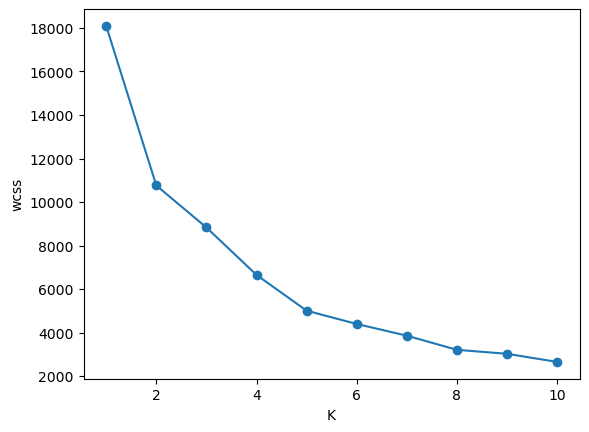

In [46]:
#Plot

plt.plot(range(1,11) , wcss , marker='o')
plt.xlabel("K")
plt.ylabel("wcss")

2.Silhouete score

Text(0, 0.5, 'silhouette_score')

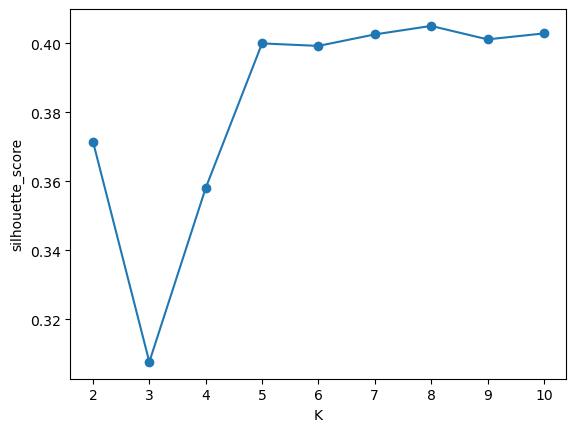

In [49]:
from sklearn.metrics import silhouette_score

scores = []

for k in range(2,11):
    kmeans = KMeans(n_clusters=k , random_state=42)
    labels = kmeans.fit_predict(X_pca)
    score = silhouette_score(X_pca , labels)
    scores.append(score)

#plot
plt.plot(range(2,11) , scores , marker='o')
plt.xlabel("K")
plt.ylabel("silhouette_score")

Text(0, 0.5, 'SS')

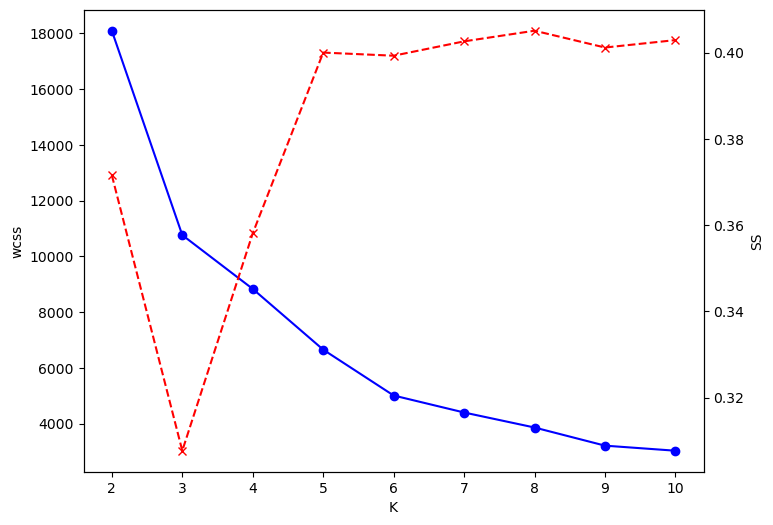

In [55]:
#Combine plo

k_range = range(2,11)
fig , ax1 = plt.subplots(figsize=(8,6))

ax1.plot(k_range , wcss[: len(k_range)] , marker='o' , color='blue')
ax1.set_xlabel("K")
ax1.set_ylabel("wcss")

ax2= ax1.twinx()
ax2.plot(k_range , scores[: len(k_range)] , marker='x' , color='red' , linestyle = '--')
ax2.set_ylabel("SS")


Clustering

In [56]:
#KMeans Alogorithm

kmeans = KMeans(n_clusters=4, random_state=42)
labels_kmeans = kmeans.fit_predict(X_pca)

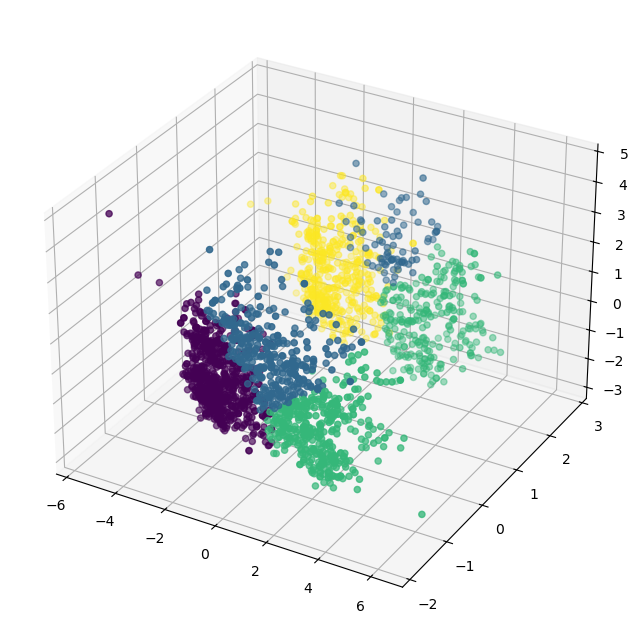

In [57]:
fig = plt.figure(figsize=(8,8))

ax = fig.add_subplot(111,projection="3d")

ax.scatter(X_pca[:,0] , X_pca[:,1] , X_pca[:,2], c=labels_kmeans)

In [58]:
#Agglomerative Clustering
from sklearn.cluster import AgglomerativeClustering

In [59]:
agg_clf = AgglomerativeClustering(n_clusters=4,linkage="ward")
labels_agg = agg_clf.fit_predict(X_pca)

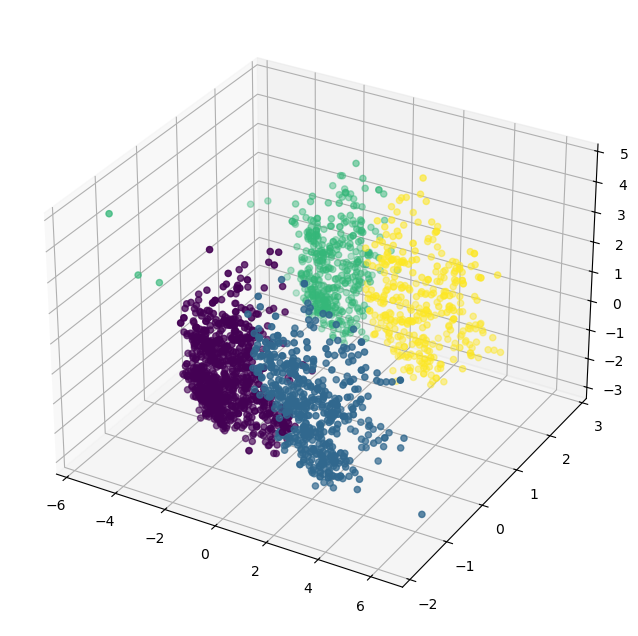

In [60]:
fig = plt.figure(figsize=(8,8))

ax = fig.add_subplot(111,projection="3d")

ax.scatter(X_pca[:,0] , X_pca[:,1] , X_pca[:,2], c=labels_agg)

Characterization of Cluster

In [70]:
X["cluster"] = labels_agg

In [71]:
X.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Education_Graduates,Education_PostGraduates,Education_Undergraduates,Living_with_Alone,Living_with_Partner,cluster
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0,3
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0,2
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0,1
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0,0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0,0


<Axes: xlabel='cluster', ylabel='count'>

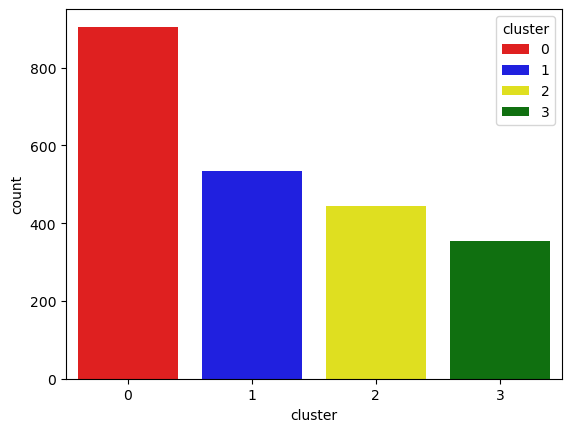

In [72]:
pal = ["red" , "blue" , "yellow" , "green"]
sns.countplot(x=X["cluster"] , palette=pal , hue=X["cluster"])

<Axes: xlabel='Total_Spending', ylabel='Income'>

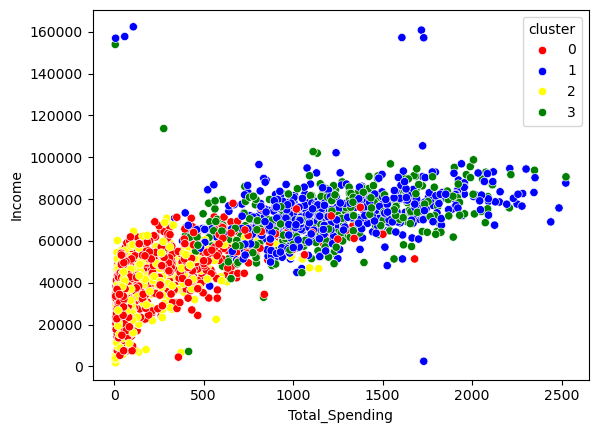

In [73]:
#Income and Spending Patterns

sns.scatterplot(x=X["Total_Spending"], y=X["Income"] , hue=X["cluster"] , palette=pal)

In [75]:
#Cluster Summary

cluster_summary = X.groupby("cluster").mean()
print(cluster_summary)

               Income    Recency  NumDealsPurchases  NumWebPurchases  \
cluster                                                                
0        39680.580110  48.914917           2.594475         3.153591   
1        72808.445693  49.202247           1.958801         5.687266   
2        36960.143018  48.319820           2.594595         2.713964   
3        70722.681303  50.504249           1.855524         5.790368   

         NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
cluster                                                                        
0                   0.969061           4.143646           6.307182  0.011050   
1                   5.498127           8.659176           3.580524  0.005618   
2                   0.837838           3.623874           6.659910  0.011261   
3                   5.014164           8.430595           3.728045  0.005666   

         Response        Age  Customer_Tenure_Days  Total_Spending  \
cluster         

Key findings and conclusion
The customer segmentation analysis reveals four different customer behaviours:
1. Cluster 0: Customers with lower purchasing power who need affordable offers and family-oriented promotions.
2. Cluster 1: High-income customers with strong purchasing activity who are suitable for loyalty and premium membership programs.
3. Cluster 2: Independent, budget-conscious customers who can be targeted through personalized digital promotions.
4. Cluster 3: High-value customers with the strongest campaign response, making them an important target for premium marketing and customer retention.
